# A command-line diagnostic

A one-step index shift leaves the numbers untouched. Can a point-error calculation notice? Build a small CLI that validates reports, demonstrates the fault, and replays supported models. [Workflow](README.md#develop-the-package-here)

In [1]:
#| default_exp cli

## Implementation

Export is explicit; running this chapter does not write package modules.

In [2]:
#| export cli
from __future__ import annotations
from timegym._internal import nonnegative_int

import argparse
from copy import deepcopy
import json
from pathlib import Path
import sys

import numpy as np

from timegym import Pipeline, Scenario, NaiveForecaster, TestReport, __version__
from timegym.diagnostics import evaluate_forecast
from timegym.evaluation import EvaluatedCase, ForecastRun
from timegym.metrics import mse
from timegym.mutations import mutate_forecast

In [3]:
#| export cli
def alignment_demo(seed=7):
    """Return a controlled fault/repair contrast; never claim automatic repair.

    A fitted drift baseline supplies the numbers. The fixture moves only the
    output index by one step. Disabling that fixture restores the original
    alignment. The numerical MSE comparator deliberately ignores the labels.
    """
    seed = nonnegative_int(seed, 'seed')
    specification = Scenario('trend', 180, 48, {'intercept': 5., 'slope': .04, 'sigma': .6})
    run = Pipeline(NaiveForecaster('drift')).run([specification], seeds=[seed])
    clean = run.cases[0]
    if clean.forecast is None:
        raise RuntimeError("The demonstration's baseline failed to produce a forecast")
    faulty = mutate_forecast(clean.forecast, 'index_shift')
    repaired = mutate_forecast(clean.forecast, 'index_shift', enabled=False)
    fault_result = evaluate_forecast(clean.case, faulty)
    repair_result = evaluate_forecast(clean.case, repaired)
    metadata = deepcopy(run.metadata)
    metadata['demonstration'] = {
        'fixture': 'index_shift', 'seed': seed,
        'repair': 'Disable the known index-shift fixture; no repair discovery is performed.',
    }
    fault_metadata = deepcopy(metadata)
    fault_metadata['pipeline_config']['replayable'] = False
    fault_metadata['pipeline_config']['model']['reason'] = (
        'This report contains an output mutation. Reproduce with timegym demo --seed ' + str(seed))
    faulty_report = TestReport([fault_result], fault_metadata)
    repaired_report = TestReport([repair_result], deepcopy(metadata))
    point_values_equal = bool(np.array_equal(faulty.point, repaired.point))
    naive_scores = [mse(clean.case.observed.to_numpy(), forecast.point)
                    for forecast in (faulty, repaired)]
    fault_codes = [d.evidence.get('code') for d in fault_result.diagnostics if d.status == 'FAIL']
    repaired_contract = any(d.name == 'forecast_contract' and d.status == 'PASS'
                            for d in repair_result.diagnostics)
    expected = ('index_mismatch' in fault_codes and repaired_contract and point_values_equal
                and naive_scores[0] == naive_scores[1]
                and repaired_report.summary['failed_cases'] == 0)
    summary = {
        'demonstration': 'same numbers, wrong forecast index', 'seed': seed,
        'point_values_unchanged': point_values_equal,
        'label_blind_mse': {'faulty': naive_scores[0], 'repaired': naive_scores[1]},
        'fault_codes': fault_codes, 'repaired_contract': 'PASS' if repaired_contract else 'FAIL',
        'expected_behavior_verified': expected,
        'scope': 'A known alignment fixture and its bypass repair; accuracy is descriptive.',
    }
    comparison = ForecastRun([
        EvaluatedCase(clean.case, faulty, fault_result, 0, 0),
        EvaluatedCase(clean.case, repaired, repair_result, 0, 1),
    ], metadata)
    return summary, faulty_report, repaired_report, comparison

In [4]:
#| export cli
def _write_demo(args):
    if args.plot and args.output is None:
        raise ValueError('--plot requires --output DIRECTORY')
    names = ['summary.json', 'faulty.json', 'repaired.json'] + (['alignment.png'] if args.plot else [])
    if args.output is not None:
        if args.output.exists() and not args.output.is_dir():
            raise ValueError('demo output must be a directory')
        occupied = [name for name in names if (args.output / name).exists()]
        if occupied:
            raise FileExistsError('Demo artifacts already exist: ' + ', '.join(occupied))
    summary, faulty, repaired, comparison = alignment_demo(args.seed)
    figure = None
    if args.plot:
        # The CLI writes an image file and must work without a display server.
        import matplotlib
        matplotlib.use('Agg')
        figure = comparison.plot_forecasts(figsize=(13, 4))
        figure.axes[0].set_title('Fault: correct values, wrong time labels', loc='left')
        figure.axes[1].set_title('Known repair: restore the requested time labels', loc='left')
    try:
        if args.output is not None:
            args.output.mkdir(parents=True, exist_ok=True)
            (args.output / 'summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False) + '\n', encoding='utf-8')
            faulty.to_json(args.output / 'faulty.json')
            repaired.to_json(args.output / 'repaired.json')
            if figure is not None:
                figure.savefig(args.output / 'alignment.png', dpi=140, bbox_inches='tight')
        return summary, 0 if summary['expected_behavior_verified'] else 1
    finally:
        if figure is not None:
            import matplotlib.pyplot as plt
            plt.close(figure)


def main(argv=None):
    """CLI exit codes: 0 expected outcome, 1 failed check/mismatch, 2 invalid use.

    Inspect succeeds if the report has no FAIL/ERROR; unsupported/inconclusive
    checks remain visible. Replay succeeds when measurements and diagnostics
    reproduce, even if the original diagnostic correctly failed.
    """
    parser = argparse.ArgumentParser(prog='timegym', description='Verify forecasting contracts and reproduce diagnostic evidence.')
    parser.add_argument('--version', action='version', version='TimeGym ' + __version__)
    commands = parser.add_subparsers(dest='command', required=True)
    demo = commands.add_parser('demo', help='Show an index fault that leaves numerical point errors unchanged')
    demo.add_argument('--seed', type=int, default=7)
    demo.add_argument('--output', type=Path, help='Write three JSON artifacts to this directory; existing files are not replaced')
    demo.add_argument('--plot', action='store_true', help='Also save the point-plot comparison (requires timegym[plots])')
    inspect = commands.add_parser('inspect', help='Validate a saved JSON report and show its diagnostic counts')
    inspect.add_argument('report', type=Path)
    replay = commands.add_parser('replay', help='Reconstruct a supported built-in model case from a validated report')
    replay.add_argument('report', type=Path)
    replay.add_argument('--case-index', type=int, default=0)
    replay.add_argument('--output', type=Path, help='Save the regenerated one-case report')
    replay.add_argument('--require-same-environment', action='store_true',
                        help='Also require matching source, dependencies, and Python version')
    args = parser.parse_args(argv)
    try:
        if args.command == 'demo':
            payload, status = _write_demo(args)
        elif args.command == 'inspect':
            report = TestReport.read(args.report)
            payload = {'summary': report.summary,
                       'scope': 'Exit 0 means no detected FAIL/ERROR, not complete capability coverage.'}
            status = int(report.summary['failed_cases'] > 0)
        else:
            report = TestReport.read(args.report)
            regenerated = report.replay_case(args.case_index)
            payload = regenerated.metadata['replay']
            required = ['metrics_match', 'diagnostics_match', 'manifest_match']
            if args.require_same_environment:
                required += ['source_matches', 'dependencies_match', 'python_matches']
            status = 0 if all(payload[key] for key in required) else 1
            if args.output is not None:
                regenerated.to_json(args.output)
    except (OSError, ValueError, TypeError, ImportError, OverflowError) as exc:
        print(f'timegym: {exc}', file=sys.stderr)
        return 2
    print(json.dumps(payload, indent=2, sort_keys=True, allow_nan=False))
    return status

In [5]:
#| export __main__
from timegym.cli import main as _entry_main

# Execute only as python -m timegym, not while developing this cell in Jupyter.
if __name__ == '__main__' and getattr(globals().get('__spec__'), 'name', None) == 'timegym.__main__':
    raise SystemExit(_entry_main())

## Same numbers, different verdict

The fixture shifts only the forecast index. The known repair removes that shift; it does not improve the model or discover a repair automatically.

{'demonstration': 'same numbers, wrong forecast index',
 'seed': 7,
 'point_values_unchanged': True,
 'label_blind_mse': {'faulty': 0.32446335273878196,
  'repaired': 0.32446335273878196},
 'fault_codes': ['index_mismatch'],
 'repaired_contract': 'PASS',
 'expected_behavior_verified': True,
 'scope': 'A known alignment fixture and its bypass repair; accuracy is descriptive.'}

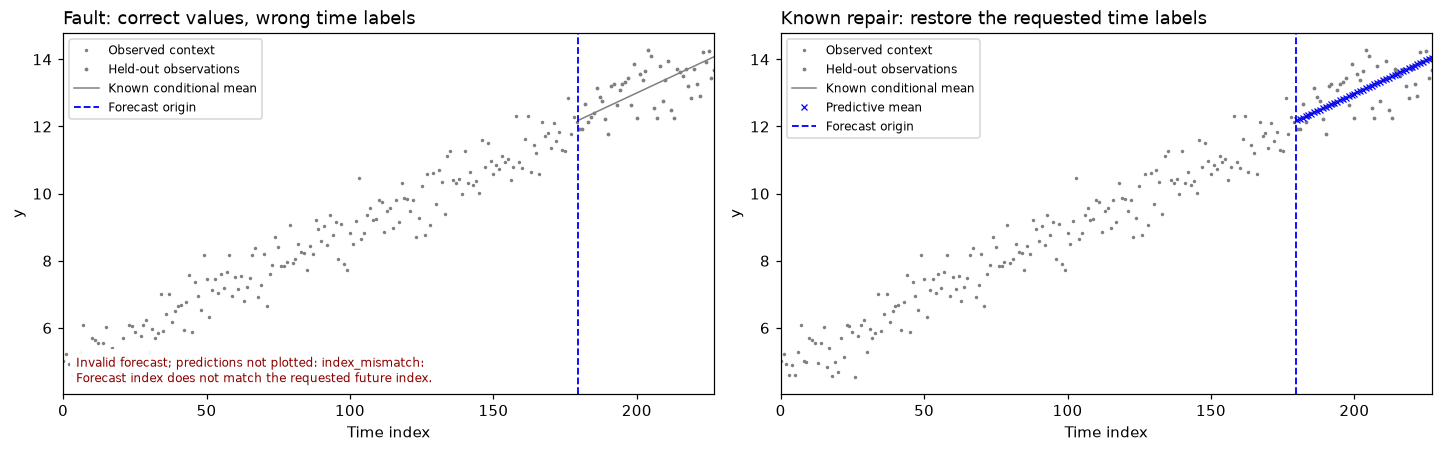

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
assert alignment_demo.__module__ == main.__module__ == __name__
summary, faulty, repaired, comparison = alignment_demo()
assert summary['expected_behavior_verified']
display(summary)
figure = comparison.plot_forecasts(figsize=(13, 4))
figure.axes[0].set_title('Fault: correct values, wrong time labels', loc='left')
figure.axes[1].set_title('Known repair: restore the requested time labels', loc='left')
plt.show()

The invalid forecast is withheld from the first panel and its contract violation is shown. Blue crosses in the repaired panel use the original prediction values. Both numerical MSE values are identical.

After exporting, run `python -m timegym demo`. Add `--output /tmp/timegym-demo --plot` to create the comparison and validated JSON reports. `timegym inspect REPORT` exits 1 for detected failures; unsupported checks remain explicit. `timegym replay REPORT` reproduces allowlisted built-in cases, with an optional environment-match gate.